<a href="https://colab.research.google.com/github/teju917/Machine_learning_lab2/blob/main/Program_8_%E2%80%93_Self_Organizing_Map_(SOM).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ORIGINAL DATASET
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4        

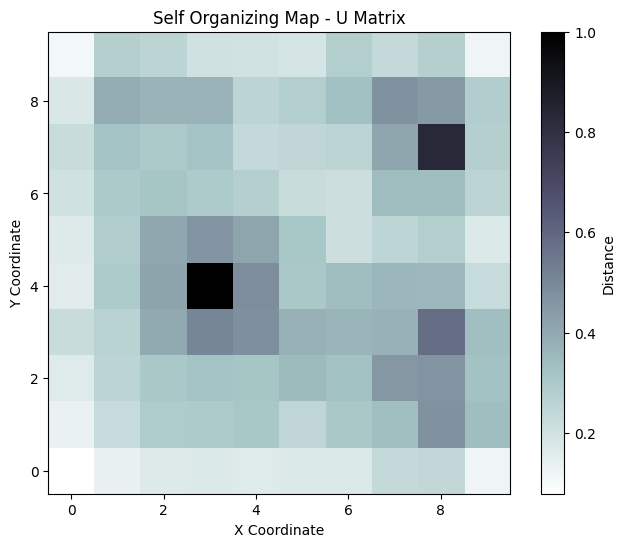

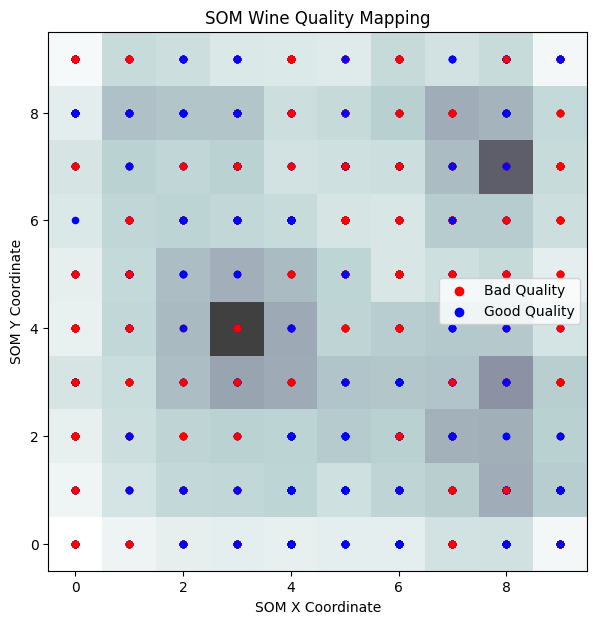

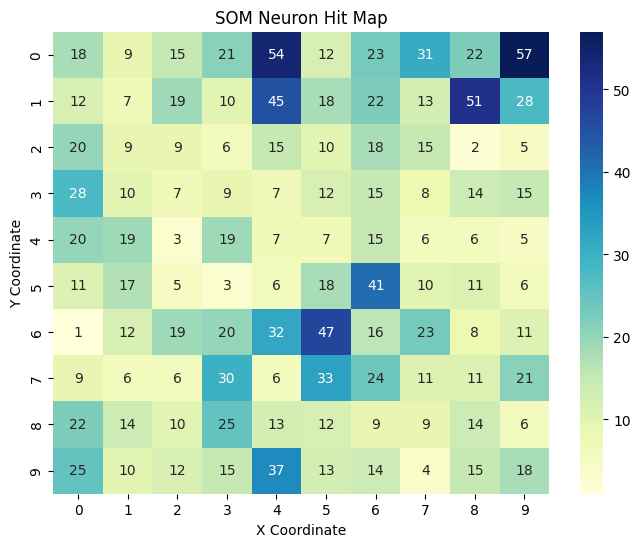


FINAL RESULT
Self Organizing Map trained successfully.
Wine samples were grouped based on similarity.
U-Matrix and Hit Map generated successfully.


In [1]:
# INSTALL LIBRARIES
!pip install minisom pandas numpy matplotlib seaborn scikit-learn -q

# IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from minisom import MiniSom
from sklearn.preprocessing import StandardScaler

# 1. READ DATASET FROM URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("ORIGINAL DATASET")
print(df.head())

print("\nDATASET INFORMATION")
print("Total examples:", len(df))
print("Number of columns:", len(df.columns))

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nQUALITY DISTRIBUTION")
print(df["quality"].value_counts().sort_index())

# 2. DATA PREPROCESSING
X = df.drop("quality", axis=1)
quality_labels = (df["quality"] >= 6).astype(int)

X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nPREPROCESSED DATASET")
print(pd.DataFrame(X_scaled, columns=X.columns).head())

print("\nDATA SHAPE:", X_scaled.shape)

# 3. CREATE SOM MODEL
som = MiniSom(
    x=10,
    y=10,
    input_len=X_scaled.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# 4. INITIALIZE AND TRAIN SOM
som.random_weights_init(X_scaled)

som.train_random(
    X_scaled,
    num_iteration=1000,
    verbose=True
)

print("\nSOM TRAINING COMPLETED")

print("Quantization Error:",
      round(som.quantization_error(X_scaled), 4))

print("Topographic Error:",
      round(som.topographic_error(X_scaled), 4))

# 5. VISUALIZE U-MATRIX
plt.figure(figsize=(8, 6))

plt.imshow(
    som.distance_map().T,
    cmap="bone_r",
    origin="lower"
)

plt.colorbar(label="Distance")
plt.title("Self Organizing Map - U Matrix")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.show()

# 6. VISUALIZE DATA ON SOM
plt.figure(figsize=(9, 7))

plt.imshow(
    som.distance_map().T,
    cmap="bone_r",
    origin="lower",
    alpha=0.75
)

colors = {0: "red", 1: "blue"}

for i, sample in enumerate(X_scaled):

    x, y = som.winner(sample)

    plt.scatter(
        x,
        y,
        color=colors[int(quality_labels.iloc[i])],
        s=20
    )

plt.scatter([], [], color="red", label="Bad Quality")
plt.scatter([], [], color="blue", label="Good Quality")

plt.title("SOM Wine Quality Mapping")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")
plt.legend()

plt.show()

# 7. NEURON HIT MAP
hit_map = np.zeros((10, 10))

for sample in X_scaled:

    x, y = som.winner(sample)

    hit_map[x, y] += 1

plt.figure(figsize=(8, 6))

sns.heatmap(
    hit_map.T,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("SOM Neuron Hit Map")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.show()

# 8. FINAL RESULT
print("\nFINAL RESULT")
print("Self Organizing Map trained successfully.")
print("Wine samples were grouped based on similarity.")
print("U-Matrix and Hit Map generated successfully.")